In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
    
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [3]:
from pyabs.core.basis import ABSBasisConfig, build_abs_basis
from pyabs.core.matrix import build_abs_matrix
from pyabs.core.wake import ThetaWake, WakeScale, ResistiveWallWake
from pyabs.solvers.eigensolvers import solve_eigenvalues, scan_over_w
from pyabs.solvers.systemsolvers import solve_system

NOTE: wth convergence is related to the resolution of wrange, not really modes.

In [4]:
n_range = np.linspace(5, 500, num = 100)

In [17]:
n_range = np.linspace(5, 500, num = 100)
wths = np.empty_like(n_range)

for i, n_max in enumerate(n_range):
    basis = build_abs_basis(np, ABSBasisConfig(n_max = n_max, q=0))
    wake = ThetaWake(W0=1)
    wrange = np.linspace(0, 3, 100)
    ans = scan_over_w(basis, wrange=wrange, determine_threshold=True, wake_model=wake)
    wths[i] =  ans.threshold

Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516
Modes 0 and -1 couple at wth = 1.1515151515151516


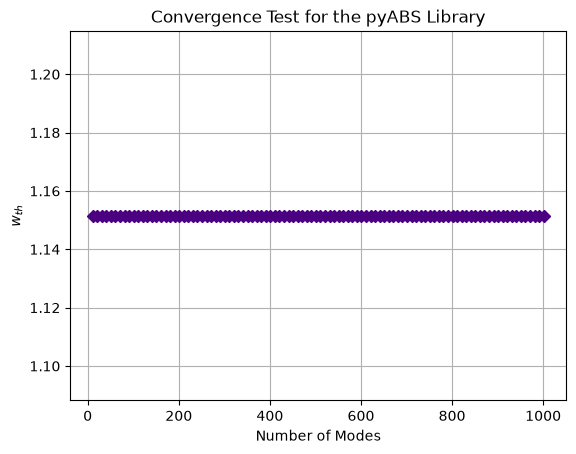

In [20]:
fig, ax = plt.subplots()
plt.title("Convergence Test for the pyABS Library")
plt.grid()
plt.plot(2*n_range+1, wths, color='indigo', marker='D')
ax.set_ylabel(r"$w_{th}$")
ax.set_xlabel(r"Number of Modes")
plt.savefig("../../plots/wthsvsmodes.png")
plt.show()

In [37]:
%%time
from tqdm.notebook import tqdm
wrange_resolution = np.linspace(10, 5000, 50)
wths_res_test = np.empty_like(wrange_resolution)

with tqdm(total=50, desc="Calculating for different resolutions") as pbar:
    for i, res in enumerate(wths_res_test):
        basis = build_abs_basis(np, ABSBasisConfig(n_max = 5, q=0))
        wake = ThetaWake(W0=1)
        wrange = np.linspace(0, 10, int(res))
        ans = scan_over_w(basis, wrange=wrange, determine_threshold=False, wake_model=wake)
        ans.determine_threshold(verbose=False)
        wths_res_test[i] = ans.threshold
        pbar.update(1)

Calculating for different resolutions:   0%|          | 0/100 [00:00<?, ?it/s]

CPU times: user 33.6 s, sys: 251 ms, total: 33.8 s
Wall time: 33.5 s


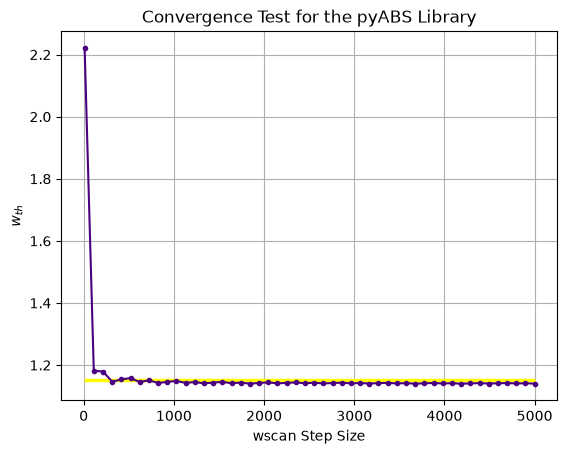

In [52]:
fig, ax = plt.subplots()
plt.title("Convergence Test for the pyABS Library")
plt.grid()
plt.hlines(y=1.1515, xmin=0, xmax=5000, color='yellow', lw = 2.5)
plt.plot(wrange_resolution, wths_res_test, color='indigo', marker='.')
ax.set_ylabel(r"$w_{th}$")
ax.set_xlabel(r"wscan Step Size")
plt.savefig("../../plots/wthsvssteps.png")
plt.show()

In [34]:
%%time
from tqdm.notebook import tqdm
n_range = np.linspace(10, 200, num = 100)
eigzero_growthrate = np.empty_like(n_range)

with tqdm(total=len(n_range), desc="Calculating for different modes") as pbar:
    for i, n_max in enumerate(n_range):
        basis = build_abs_basis(np, ABSBasisConfig(n_max = int(n_max), q=0))
        wake = ThetaWake(W0=1)
        matrix = build_abs_matrix(basis, wake_model=wake, scale=WakeScale(w=1.3))
        solution = solve_system(matrix, A0=1)
        eigzero_growthrate[int(i)] = np.max(np.abs(solution.eigenvalues.imag))
        pbar.update(1)

Calculating for different modes:   0%|          | 0/100 [00:00<?, ?it/s]

CPU times: user 3min 21s, sys: 127 ms, total: 3min 21s
Wall time: 19.2 s


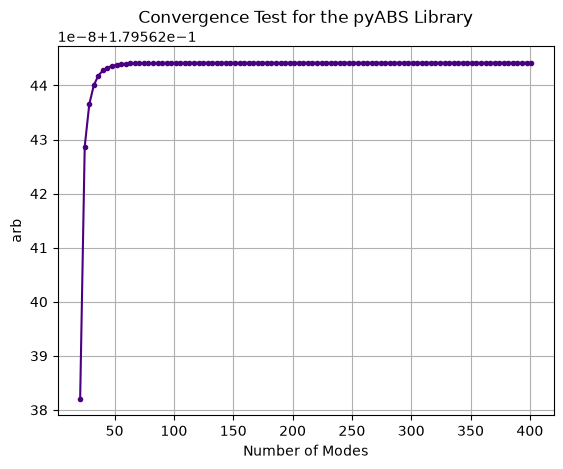

In [35]:
fig, ax = plt.subplots()
plt.title("Convergence Test for the pyABS Library")
plt.grid()
#plt.hlines(y=1.1515, xmin=0, xmax=5000, color='yellow', lw = 2.5)
plt.plot(2*n_range+1, eigzero_growthrate, color='indigo', marker='.', label=r"$\nu$ Max Growth Rate")
ax.set_ylabel("arb")
ax.set_xlabel(r"Number of Modes")
plt.show()

In [5]:
%%time
from tqdm.notebook import tqdm
n_rangekmax = np.linspace(10, 2000, num = 100)
kmax = np.empty_like(n_rangekmax)

with tqdm(total=len(n_rangekmax), desc="Calculating for different modes") as pbar:
    for i, n_max in enumerate(n_rangekmax):
        basis = build_abs_basis(np, ABSBasisConfig(n_max = int(n_max), q=40))
        wake = ThetaWake(W0=1)
        matrix = build_abs_matrix(basis, wake_model=wake, scale=WakeScale(w=80.0))
        solution = solve_system(matrix, A0=1)
        kmax[i] = np.log(np.max(solution.compute_amplification_factors()))
        pbar.update(1)

Calculating for different modes:   0%|          | 0/100 [00:00<?, ?it/s]

CPU times: user 7min 4s, sys: 129 ms, total: 7min 4s
Wall time: 1min 41s


KeyboardInterrupt: 

In [1]:
fig, ax = plt.subplots()
plt.title("Convergence Test for the pyABS Library")
plt.grid()
#plt.hlines(y=1.1515, xmin=0, xmax=5000, color='yellow', lw = 2.5)
plt.plot(2*n_rangekmax+1, kmax,color='red', marker='.', label = "log(kmax)")
ax.set_ylabel("arb")
ax.set_xlabel(r"Number of Modes")
plt.show()

NameError: name 'plt' is not defined